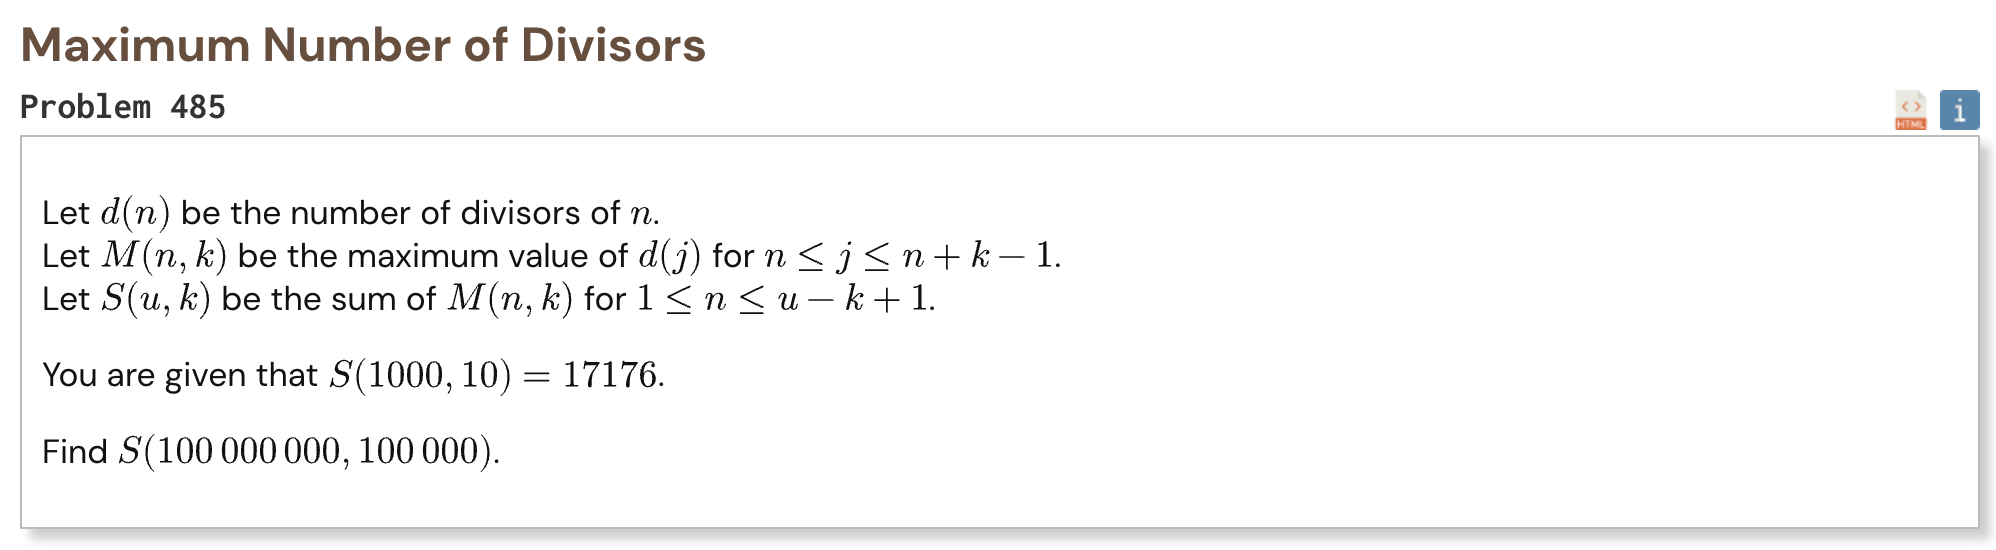

## Initial approach

- compute the number of divisors for every integer up to the limit
- use a linear sieve so all divisor counts are built efficiently
- scan the divisor counts with a sliding window of length 100000
- keep possible maximum values in a monotonic deque
- remove values that leave the window or can never become the maximum again
- add the current maximum for every valid window

In [1]:
%%time

from array import array
from collections import deque

U = 100_000_000
K = 100_000

spf = array("I", [0]) * (U + 1)
exponent = bytearray(U + 1)
divisors = array("H", [0]) * (U + 1)
primes = array("I")

divisors[1] = 1

for n in range(2, U + 1):
    if spf[n] == 0:
        spf[n] = n
        exponent[n] = 1
        divisors[n] = 2
        primes.append(n)

    for p in primes:
        value = n * p

        if value > U:
            break

        spf[value] = p

        if p == spf[n]:
            exponent[value] = exponent[n] + 1
            divisors[value] = (
                divisors[n]
                // (exponent[n] + 1)
                * (exponent[value] + 1)
            )
            break

        exponent[value] = 1
        divisors[value] = divisors[n] * 2

window = deque()
result = 0

for i in range(1, U + 1):
    while window and divisors[window[-1]] <= divisors[i]:
        window.pop()

    window.append(i)

    while window[0] <= i - K:
        window.popleft()

    if i >= K:
        result += divisors[window[0]]

print("Result:", result)

Result: 51281274340
CPU times: user 59.6 s, sys: 277 ms, total: 59.9 s
Wall time: 59.9 s
